In [1]:
# You only need to run this if the following imports fail for missing one of these packages
#%pip install uproot numpy matplotlib

import uproot
import numpy as np
import matplotlib.pyplot as plt

## Define organ names and masses

In [2]:
# I got these from the simulation output

organs = [
    "Brain", "Head", "Heart", "LeftAdrenal", "LeftArmBone",
    "LeftBreast", "LeftClavicle", "LeftKidney", "LeftLeg",
    "LeftLegBone", "LeftLung", "LeftOvary", "LeftScapula",
    "LeftTeste", "LowerLargeIntestine", "MaleGenitalia",
    "MiddleLowerSpine", "Pancreas", "Pelvis", "RibCage",
    "RightAdrenal", "RightArmBone", "RightBreast",
    "RightClavicle", "RightKidney", "RightLeg", "RightLegBone",
    "RightLung", "RightOvary", "RightScapula", "RightTeste",
    "Skull", "SmallIntestine", "Spleen", "Stomach", "Thymus",
    "Thyroid", "Trunk", "UpperLargeIntestine", "UpperSpine",
    "UrinaryBladder", "Uterus"
]

mass = np.array([
    1451, 4595.45, 111, 7.751, 1217.78, 111, 20.31,
    141.85, 10252.1, 2080.29, 111, 111, 149.224, 18.54,
    339.60, 226.53, 1120.57, 60.17, 900.10, 1028.56,
    7.751, 1217.78, 111, 20.31, 142.372, 10252.1,
    2080.29, 111, 111, 149.805, 18.54, 1257.28,
    1006.21, 173.625, 396.86, 24.8, 111, 43406.1,
    429.275, 187.792, 45.1, 111
])

print(f"Number of organs: {len(organs)}")
print(f"Number of masses: {len(mass)}")

Number of organs: 42
Number of masses: 42


## Read the ROOT files, calculate total energy deposit in each organ

In [3]:
files = [
    "human_phantom_t0.root",
    "human_phantom_t1.root",
    "human_phantom_t2.root",
    "human_phantom_t3.root"
]

# Initialise the energy sum for each organ
total_edep = np.zeros(len(organs))

# Read and process each file
for filename in files:
    print(f"Reading {filename}")

    with uproot.open(filename) as file:
        ntuple = file["human_phantom_ntuple/1"]

        organID = ntuple["organID"].array(library="np")
        edep = ntuple["edep"].array(library="np")

        for i in range(len(edep)):
            organ = int(organID[i])
            total_edep[organ] += edep[i]

print("Energy accumulation complete.")

Reading human_phantom_t0.root
Reading human_phantom_t1.root
Reading human_phantom_t2.root
Reading human_phantom_t3.root
Energy accumulation complete.


## Plot the absorbed energy

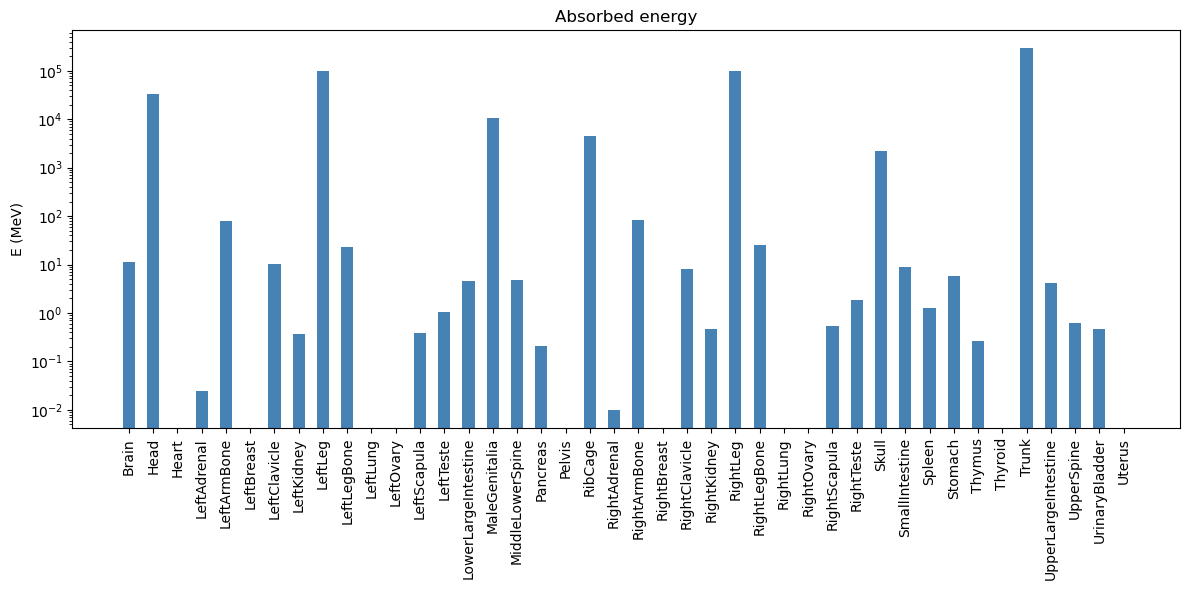

In [7]:
plt.figure(figsize=(12, 6))
plt.bar(organs, total_edep, width=0.5, color="steelblue")
plt.title("Absorbed energy")
plt.ylabel("E (MeV)")
plt.yscale('log')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## Exercise -- calculate the absorbed dose

Extend the notebook to calculate and plot the absorbed dose for each organ.
1. Create an array to store the dose for each organ.
2. Use the total deposited energy and the corresponding organ mass.
3. Convert the result to gray (Gy).
4. Make a bar plot of dose versus organ.

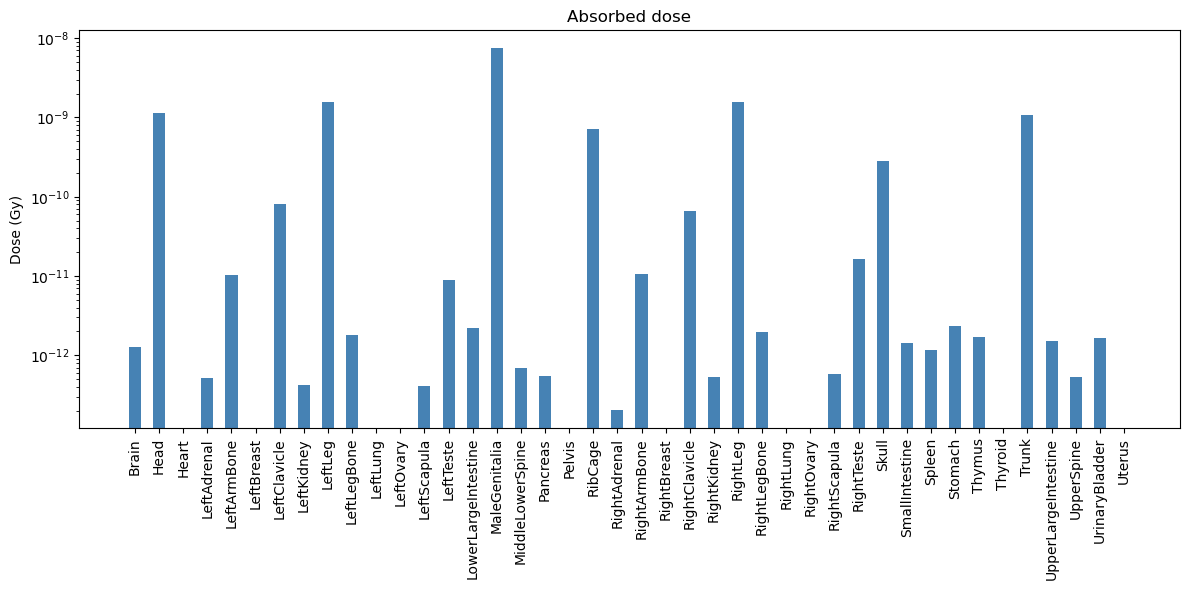

In [9]:
energy_J = total_edep * 1.60218e-13
mass_kg = mass * 1e-3
dose = energy_J / mass_kg

plt.figure(figsize=(12, 6))
plt.bar(organs, dose, width=0.5, color="steelblue")

plt.title("Absorbed dose")
plt.ylabel("Dose (Gy)")
plt.yscale('log')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

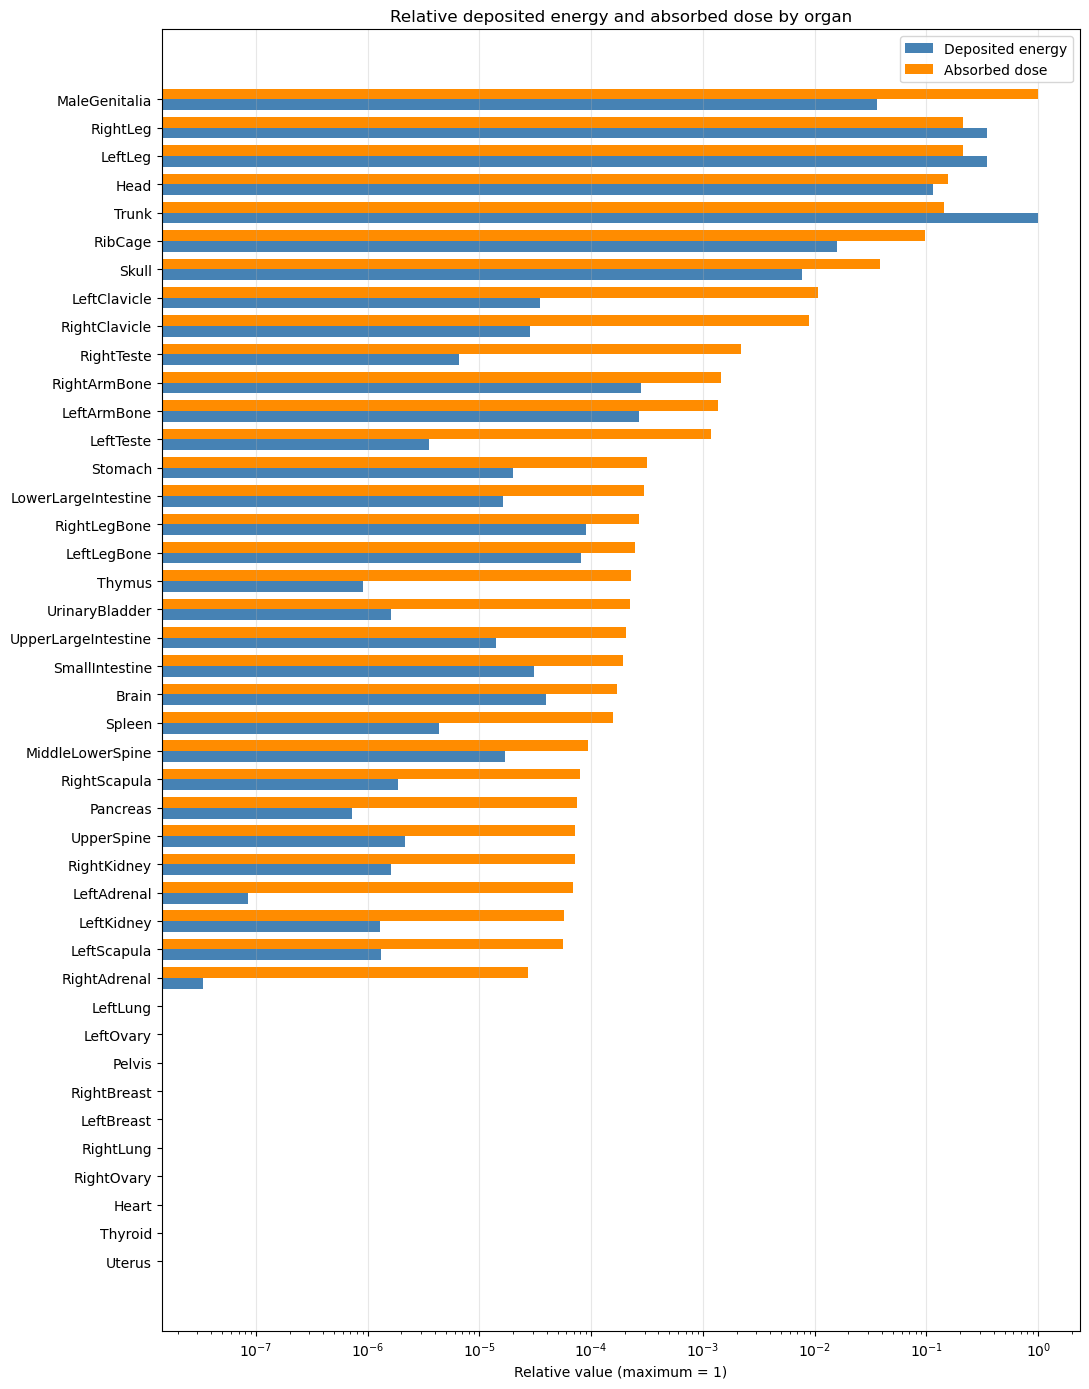

In [13]:

# Rank organs by absorbed dose, from highest to lowest
order = np.argsort(dose)

# Normalise both quantities to their respective maxima
energy_relative = total_edep / np.max(total_edep)
dose_relative = dose / np.max(dose)

# Plot two horizontal bars per organ
y = np.arange(len(organs))
bar_height = 0.38

fig, ax = plt.subplots(figsize=(11, 14))

ax.barh(
    y - bar_height / 2,
    energy_relative[order],
    height=bar_height,
    label="Deposited energy",
    color="steelblue"
)

ax.barh(
    y + bar_height / 2,
    dose_relative[order],
    height=bar_height,
    label="Absorbed dose",
    color="darkorange"
)

ax.set_yticks(y)
ax.set_yticklabels(np.array(organs)[order])
ax.set_xlabel("Relative value (maximum = 1)")
ax.set_title("Relative deposited energy and absorbed dose by organ")
ax.legend()
ax.grid(axis="x", alpha=0.3)
ax.set_xscale('log')

# Put the highest-dose organ at the top
#ax.invert_yaxis()

plt.tight_layout()
plt.show()
